# Owner: SONG Haoyu, M4a
# Can combining models help us find more serious injuries?

We compare bagging, boosting, soft voting and stacking with the logistic baseline and M3's tuned models. We start with whole accidents covering about 30,000 people, then make out-of-fold predictions for everyone in the training years. All the results here use 2019–2023. We leave the test years for the final notebook.

Run this notebook first, then `05_catboost_interpretation.ipynb`, then `05b_final_evaluation.ipynb`. The expensive fits are cached locally under `data/m4/`; data, model settings and code are checked before a cache is reused.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json, joblib, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.config import RANDOM_STATE, RESULTS_DIR, FIGURES_DIR
from src.models.m4_common import (CACHE, environment, fingerprint, load_training,
    grouped_folds, oof_predict, score_oof, tune_candidates)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RUN_ID = fingerprint()
print('Run:', RUN_ID)
print(environment())
X, y, groups, meta = load_training()
print(f'{len(X):,} training people; {groups.nunique():,} accidents; KSI rate {y.mean():.2%}')
folds = grouped_folds(X, y, groups, 'full_train')
print('Five accident-grouped folds are ready.')

Run: 734efc841d8b51f8
{'python': '3.12.14', 'numpy': '2.0.2', 'pandas': '2.3.3', 'scikit-learn': '1.9.1', 'catboost': '1.2.10', 'shap': '0.54.1'}


619,552 training people; 273,226 accidents; KSI rate 18.03%


Five accident-grouped folds are ready.


## 1. Pick up M3's best settings

The grid search is already done. We load its settings rather than choosing new ones from the test data. Each model gets its own preprocessing pipeline: scaled inputs for logistic regression and the tree preprocessor for trees. We leave SVM and kNN out because they are much harder to run at this scale.

M3 used different sample sizes for its searches, so its published search scores are context, not a perfectly matched leaderboard. Our next table uses the same people and folds for every model.

We store the forest's transformed matrix densely to speed up fitting. The feature values and M3 hyperparameters are unchanged, but sparse and dense tree implementations can resolve ties differently. We therefore rerun its validation predictions and the ensembles that use it.

In [2]:
from src.models.baseline import logistic_baseline
from src.models.ensembles import (automl_models, ensemble_candidates, voting_model,
    compare_on_subsample, nested_stacking_oof)
automl = automl_models()
# Same encoded columns, dense storage to keep full-data forests practical.
automl['Random forest'].named_steps['prep'].set_params(sparse_threshold=0)
bag_candidates, boost_candidates = ensemble_candidates()
bases = {'logistic': automl['Logistic regression'], 'forest': automl['Random forest']}
voting = voting_model(bases)
display(pd.DataFrame(json.loads((RESULTS_DIR / 'automl_v01_best_params.json').read_text())).T)
# A predeclared small search. Whole accidents stay together in each fold.
bagging, bag_search = tune_candidates(bag_candidates, X, y, groups, 'bagging', RUN_ID, max_people=30_000)
boosting, boost_search = tune_candidates(boost_candidates, X, y, groups, 'boosting', RUN_ID, max_people=30_000)
display(bag_search)
display(boost_search)

,params,cv_pr_auc_mean,cv_pr_auc_std,train_pr_auc_mean,subsample_people,search_time_s
Logistic regression,{'model__C': 0.1},0.58972,0.006723,0.598786,99999,285
Decision tree,"{'model__max_depth': 16, 'model__min_samples_l...",0.53043,0.010448,0.572287,29999,50
Random forest,"{'model__max_depth': None, 'model__min_samples...",0.579693,0.011072,0.999917,29999,126
k-nearest neighbours,"{'model__n_neighbors': 25, 'model__weights': '...",0.539631,0.007239,0.999999,19998,348
SVM,{'model__C': 1},0.580525,0.01233,0.800352,10000,90


bagging_bag_20_0.5: fold 1/5 loaded


bagging_bag_20_0.5: fold 2/5 loaded


bagging_bag_20_0.5: fold 3/5 loaded


bagging_bag_20_0.5: fold 4/5 loaded


bagging_bag_20_0.5: fold 5/5 loaded


... (23 outputs left out)

boosting_hgb_31_0.05_250: fold 4/5 loaded


boosting_hgb_31_0.05_250: fold 5/5 loaded


,model,scored_on,pr_auc,roc_auc,precision,recall,f2,threshold,predicted_ksi_share,n_people
2,bag_40_0.8,out-of-fold (5 grouped folds),0.559918,0.849845,0.356039,0.870650,0.675406,0.411325,0.437996,29998
0,bag_20_0.5,out-of-fold (5 grouped folds),0.549634,0.845441,0.329506,0.897264,0.667303,0.373639,0.487733,29998
1,bag_40_0.5,out-of-fold (5 grouped folds),0.549150,0.846122,0.346827,0.870650,0.668668,0.409453,0.449630,29998


,model,scored_on,pr_auc,roc_auc,precision,recall,f2,threshold,predicted_ksi_share,n_people
2,hgb_31_0.05_250,out-of-fold (5 grouped folds),0.604600,0.874212,0.393422,0.874930,0.702880,0.369138,0.398327,29998
1,hgb_31_0.1_150,out-of-fold (5 grouped folds),0.601180,0.872050,0.414962,0.845524,0.700216,0.406988,0.364958,29998
0,hgb_15_0.1_150,out-of-fold (5 grouped folds),0.596195,0.872229,0.389952,0.879769,0.703130,0.395418,0.404094,29998


## 2. The same 30,000-person benchmark for everyone

Bagging averages trees trained on bootstrap samples. Soft voting averages the logistic and random-forest probabilities. Boosting grows trees in sequence to improve the loss. The error bars below show variation across five validation folds, not confidence intervals.

The settings for bagging and boosting were selected on a training subsample, so these scores are development results. They are not an unbiased estimate of the entire tuning procedure. We still have the untouched later years for that final check.

Logistic baseline: validation AP 0.5790


Logistic regression: validation AP 0.5829


Decision tree: validation AP 0.5304


Random forest: validation AP 0.5790


Bagging: validation AP 0.5574


Boosting: validation AP 0.5965


Soft voting: validation AP 0.6031


,model,cv_pr_auc_mean,cv_pr_auc_std,train_pr_auc_mean,subsample_people,fit_time_s
6,Soft voting,0.6031,0.0081,0.9716,29999,2.2215
5,Boosting,0.5965,0.0110,0.7509,29999,5.6224
1,Logistic regression,0.5829,0.0133,0.6046,29999,0.4556
0,Logistic baseline,0.5790,0.0134,0.6052,29999,0.5460
3,Random forest,0.5790,0.0060,0.9999,29999,1.7385
4,Bagging,0.5574,0.0122,0.5850,29999,1.7000
2,Decision tree,0.5304,0.0104,0.5723,29999,0.5031


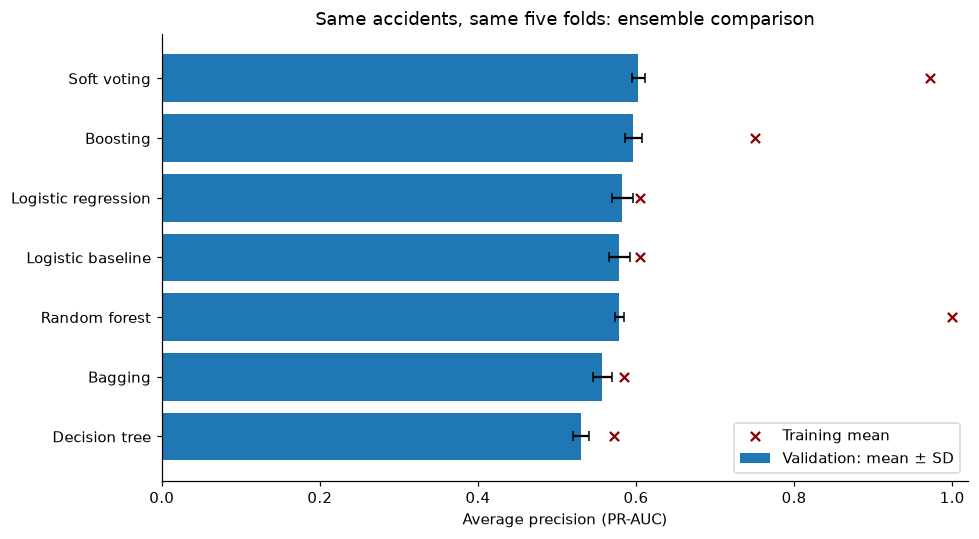

Best validation score: Soft voting


In [3]:
comparison_models = {'Logistic baseline': logistic_baseline(), **automl,
    'Bagging': bagging, 'Boosting': boosting, 'Soft voting': voting}
comparison = compare_on_subsample(comparison_models, X, y, groups, RUN_ID)
comparison.to_csv(RESULTS_DIR / 'ensembles.csv', index=False)
display(comparison.round(4))
fig, ax = plt.subplots(figsize=(9, 5))
ordered = comparison.sort_values('cv_pr_auc_mean')
ax.barh(ordered.model, ordered.cv_pr_auc_mean, xerr=ordered.cv_pr_auc_std, capsize=3, label='Validation: mean ± SD')
ax.scatter(ordered.train_pr_auc_mean, ordered.model, marker='x', color='darkred', label='Training mean')
ax.set(xlabel='Average precision (PR-AUC)', title='Same accidents, same five folds: ensemble comparison', xlim=(0, 1.02))
ax.legend(loc='lower right'); fig.tight_layout()
fig.savefig(FIGURES_DIR / 'm4_ensembles.png', dpi=180)
plt.show()
print('Best validation score:', comparison.iloc[0]['model'])

## 3. Predictions for all training years

Every person is predicted by a model that did not train on their accident. We use the shared five folds for every model. The F2 threshold is chosen from these training OOF predictions, so threshold-based scores here are descriptive development scores. We freeze those thresholds before the final test.

We also run M3's three scalable models on the full training set, because the handoff contained the search results but no full-data OOF predictions.

In [4]:
models = {'Logistic baseline': logistic_baseline(), **automl, 'Bagging': bagging, 'Boosting': boosting}
oof, rows = {}, []
for name, model in models.items():
    key = name.lower().replace(' ', '_')
    oof[name] = oof_predict(model, X, y, groups, folds, key, RUN_ID)
    rows.append(score_oof(name, y, oof[name]))
    display(pd.DataFrame(rows).round(4))
oof['Soft voting'] = (oof['Logistic regression'] + oof['Random forest']) / 2
models['Soft voting'] = voting
rows.append(score_oof('Soft voting', y, oof['Soft voting']))
# Persist this stage before the more expensive nested stacking.
joblib.dump({'run_id': RUN_ID, 'models': models, 'oof': oof, 'rows': rows,
             'bases': bases, 'index': X.index.to_numpy()}, CACHE / 'ensembles_stage.joblib')

logistic_baseline: fold 1/5 loaded


logistic_baseline: fold 2/5 loaded


logistic_baseline: fold 3/5 loaded


logistic_baseline: fold 4/5 loaded


logistic_baseline: fold 5/5 loaded


,model,scored_on,pr_auc,roc_auc,precision,recall,f2,threshold,predicted_ksi_share
0,Logistic baseline,out-of-fold (5 grouped folds),0.5888,0.8722,0.3954,0.8757,0.7045,0.413,0.3993


... (27 outputs left out)

boosting: fold 4/5 loaded


boosting: fold 5/5 loaded


,model,scored_on,pr_auc,roc_auc,precision,recall,f2,threshold,predicted_ksi_share
0,Logistic baseline,out-of-fold (5 grouped folds),0.5888,0.8722,0.3954,0.8757,0.7045,0.4130,0.3993
1,Logistic regression,out-of-fold (5 grouped folds),0.5889,0.8722,0.3959,0.8750,0.7045,0.4147,0.3985
2,Decision tree,out-of-fold (5 grouped folds),0.5834,0.8616,0.3887,0.8584,0.6913,0.4416,0.3982
3,Random forest,out-of-fold (5 grouped folds),0.6140,0.8775,0.3996,0.8777,0.7082,0.1582,0.3960
4,Bagging,out-of-fold (5 grouped folds),0.6036,0.8718,0.3882,0.8777,0.7010,0.4127,0.4076
5,Boosting,out-of-fold (5 grouped folds),0.6302,0.8842,0.4162,0.8715,0.7151,0.4394,0.3775


['/Users/colder/Documents/GitHub/road-accident-severity/data/m4/ensembles_stage.joblib']

## 4. Stacking without sharing validation labels

Stacking lets a logistic model learn how to combine the two base probabilities. There is a subtle trap here: taking one global OOF table and cross-validating a second model on it can still leak labels across the outer folds.

For each of our five outer folds, we build a fresh three-fold, accident-grouped OOF table using only the outer training accidents. The final logistic model learns from that inner table. We then predict the outer validation accidents with base models trained only on the outer training fold. Three inner folds keep the extra training manageable; the outer comparison still uses the same five folds. All fitted preprocessing stays inside each fit.

In [5]:
base_oof = {'logistic': oof['Logistic regression'], 'forest': oof['Random forest']}
oof['Stacking'] = nested_stacking_oof(bases, base_oof, X, y, groups, folds, RUN_ID)
rows.append(score_oof('Stacking', y, oof['Stacking']))
train_table = pd.DataFrame(rows)
train_table.to_csv(RESULTS_DIR / 'ensembles_train.csv', index=False)
automl_table = train_table[train_table.model.isin(automl)].copy()
automl_table['threshold_rule'] = 'best F2'
automl_table.to_csv(RESULTS_DIR / 'automl_v01_full_train.csv', index=False)
thresholds = dict(zip(train_table.model, train_table.threshold))
ensemble_names = ['Bagging', 'Boosting', 'Soft voting', 'Stacking']
best_ensemble = train_table[train_table.model.isin(ensemble_names)].sort_values('pr_auc', ascending=False).iloc[0].model
best_automl = train_table[train_table.model.isin(automl)].sort_values('pr_auc', ascending=False).iloc[0].model
bundle = {'run_id': RUN_ID, 'models': models, 'oof': oof, 'thresholds': thresholds,
          'best_ensemble': best_ensemble, 'best_automl': best_automl, 'bases': bases,
          'base_oof': base_oof, 'index': X.index.to_numpy()}
joblib.dump(bundle, CACHE / 'ensembles.joblib')
display(train_table.sort_values('pr_auc', ascending=False).round(4))
print('Frozen choices:', best_automl, 'and', best_ensemble)

stack_outer0_logistic: fold 1/3 loaded


stack_outer0_logistic: fold 2/3 loaded


stack_outer0_logistic: fold 3/3 loaded


stack_outer0_forest: fold 1/3 loaded


stack_outer0_forest: fold 2/3 loaded


stack_outer0_forest: fold 3/3 loaded


... (32 outputs left out)

Stacking outer fold 5/5 finished


/Users/colder/Documents/GitHub/road-accident-severity/.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/colder/Documents/GitHub/road-accident-severity/.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/colder/Documents/GitHub/road-accident-severity/.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/colder/Documents/GitHub/road-accident-severity/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/colder/Documents/GitHub/road-accident-severity/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: Run

,model,scored_on,pr_auc,roc_auc,precision,recall,f2,threshold,predicted_ksi_share
5,Boosting,out-of-fold (5 grouped folds),0.6302,0.8842,0.4162,0.8715,0.7151,0.4394,0.3775
7,Stacking,out-of-fold (5 grouped folds),0.6250,0.8812,0.4085,0.8728,0.7111,0.1135,0.3852
6,Soft voting,out-of-fold (5 grouped folds),0.6249,0.8812,0.4086,0.8726,0.7111,0.2999,0.3850
3,Random forest,out-of-fold (5 grouped folds),0.6140,0.8775,0.3996,0.8777,0.7082,0.1582,0.3960
4,Bagging,out-of-fold (5 grouped folds),0.6036,0.8718,0.3882,0.8777,0.7010,0.4127,0.4076
1,Logistic regression,out-of-fold (5 grouped folds),0.5889,0.8722,0.3959,0.8750,0.7045,0.4147,0.3985
0,Logistic baseline,out-of-fold (5 grouped folds),0.5888,0.8722,0.3954,0.8757,0.7045,0.4130,0.3993
2,Decision tree,out-of-fold (5 grouped folds),0.5834,0.8616,0.3887,0.8584,0.6913,0.4416,0.3982


Frozen choices: Random forest and Boosting


## 5. How much could the scores vary?

We sample whole accidents with replacement 1,000 times, keeping every person in each selected accident. Repeated accidents count repeatedly. Sampling people independently would miss the dependence between people in the same crash.

The interval describes sampling uncertainty for these fixed predictions; it does not include retraining or model-selection uncertainty. We use exactly the same sampled accidents for model differences. An interval excluding zero is evidence of a difference under this resampling scheme, not proof that an improvement will hold everywhere. Our implementation caches probability ranks, and a test checks it against literally duplicating accident rows and calling the shared metric function.

In [6]:
from src.evaluation.bootstrap import bootstrap_comparison
ci, paired = bootstrap_comparison(y, oof, groups, thresholds, n_boot=1000, reference='Logistic baseline')
ci.to_csv(RESULTS_DIR / 'm4_train_ci.csv', index=False)
paired.to_csv(RESULTS_DIR / 'm4_train_paired.csv', index=False)
display(ci.query("metric == 'pr_auc'").round(4))
display(paired.query("metric == 'pr_auc'").round(4))
print('Bootstrap details:', ci.attrs)
baseline_ci = ci.query("model == 'Logistic baseline' and metric == 'pr_auc'").iloc[0]
print('Published baseline AP 0.5887 lies in the interval:', baseline_ci.low <= 0.5887 <= baseline_ci.high)
ci.query("model == 'Logistic baseline'").drop(columns='model').set_index('metric').to_csv(RESULTS_DIR / 'm4_baseline_ci.csv')

,model,metric,estimate,low,high
0,Logistic baseline,pr_auc,0.5888,0.5856,0.5924
7,Logistic regression,pr_auc,0.5889,0.5857,0.5924
14,Decision tree,pr_auc,0.5834,0.5804,0.5866
21,Random forest,pr_auc,0.6140,0.6109,0.6172
28,Bagging,pr_auc,0.6036,0.6004,0.6069
35,Boosting,pr_auc,0.6302,0.6272,0.6334
42,Soft voting,pr_auc,0.6249,0.6219,0.6282
49,Stacking,pr_auc,0.6250,0.6219,0.6282


,model,reference,metric,estimate,low,high
0,Logistic regression,Logistic baseline,pr_auc,0.0001,-0.0000,0.0001
7,Decision tree,Logistic baseline,pr_auc,-0.0054,-0.0078,-0.0030
14,Random forest,Logistic baseline,pr_auc,0.0252,0.0230,0.0273
21,Bagging,Logistic baseline,pr_auc,0.0148,0.0126,0.0168
28,Boosting,Logistic baseline,pr_auc,0.0414,0.0396,0.0431
35,Soft voting,Logistic baseline,pr_auc,0.0361,0.0345,0.0377
42,Stacking,Logistic baseline,pr_auc,0.0362,0.0345,0.0377


Bootstrap details: {'n_boot': 1000, 'rejected_single_class': 0, 'n_accidents': 273226, 'seed': 42}
Published baseline AP 0.5887 lies in the interval: True


## 6. Where does our best ensemble miss people?

We look at OOF errors by road user, area, speed limit, light, age band and year. Counts matter: a striking percentage from a tiny group is not enough to support a strong conclusion. These are people who were already involved in recorded injury accidents, not the whole driving population.

The calibration curve also matters. Class weighting can help recall while moving probabilities away from observed KSI rates. We do not automatically treat a score of 0.7 as a calibrated 70% risk.

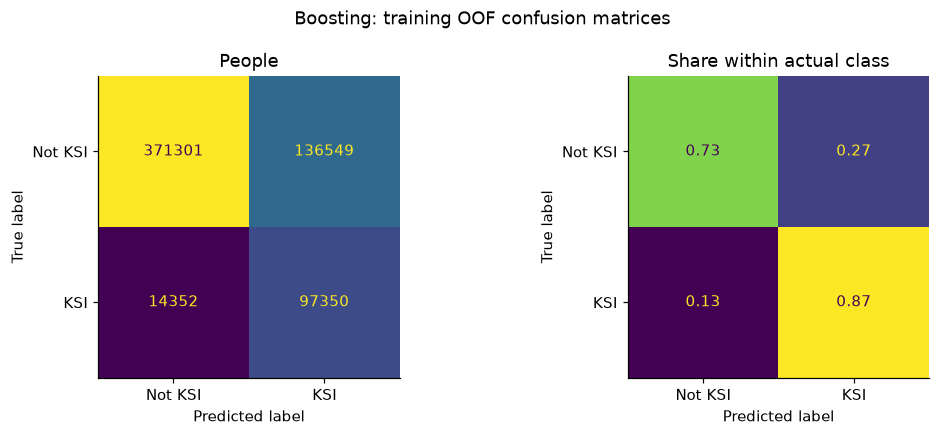

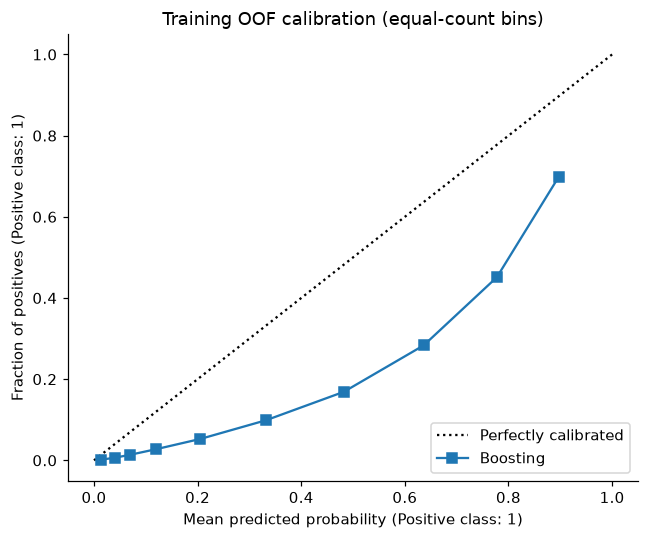

,group,value,n_people,n_ksi,tp,fn,fp,recall,precision,mean_prediction,observed_ksi
25,vma,31.0,3,1,0,1,0,0.000000,NaN,0.226538,0.333333
1,road_user,Bus / coach,7211,133,13,120,43,0.097744,0.232143,0.085743,0.018444
51,age_band,Missing,8336,17,8,9,26,0.470588,0.235294,0.010775,0.002039
26,vma,35.0,37,6,4,2,15,0.666667,0.210526,0.395957,0.162162
5,road_user,Heavy goods vehicle,14074,925,620,305,1050,0.670270,0.371257,0.176632,0.065724
15,vma,100.0,101,26,18,8,25,0.692308,0.418605,0.427263,0.257426
23,vma,25.0,263,20,14,6,50,0.700000,0.218750,0.285907,0.076046
4,road_user,E-scooter / personal device,8907,1464,1039,425,2310,0.709699,0.310242,0.383773,0.164365
11,road_user,Van,38198,2881,2097,784,3848,0.727872,0.352733,0.190328,0.075423
24,vma,30.0,67193,6952,5291,1661,10390,0.761076,0.337415,0.250215,0.103463


,road_user,agg,vma,missed_people,mean_score
40,Car,2,50.0,3370,0.214988
28,Car,1,80.0,1118,0.333043
107,Motorcycle >50cc,2,50.0,789,0.316735
29,Car,1,90.0,758,0.244406
138,Pedestrian,2,50.0,642,0.345860
27,Car,1,70.0,609,0.280303
93,Moped <50cc,2,50.0,577,0.325482
31,Car,1,110.0,569,0.249557
32,Car,1,130.0,506,0.322135
10,Bicycle,2,50.0,436,0.317055


At threshold 0.4394, we missed 14,352 of 111,702 KSI people. The Brier score is 0.1439. Among groups with at least 100 people and 30 KSI cases, the lowest recall is 9.8% for road_user=Bus / coach. The table shows where misses happen; it cannot tell us which missing measurement caused a miss. Actual impact speed, distraction and emergency response detail could help, but are not established explanations here.


In [7]:
from src.evaluation.m4_analysis import error_analysis
error_tables = error_analysis(meta, y, oof[best_ensemble], thresholds[best_ensemble], best_ensemble, 'ensemble')
display(error_tables['groups'].sort_values('recall').head(20))
display(error_tables['false_negatives'].head(15))
print(error_tables['summary'])

## What we can take from this

The tables above tell us whether the extra complexity helped on the training-year validation folds. We keep the chosen ensemble and its threshold fixed from here. The later test years will be evaluated together with the logistic baseline, the best AutoML model and CatBoost in the final notebook.

Reference: [scikit-learn stacking documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html). The internal CV trains the final estimator; it is not itself an outer evaluation of the whole stack.

## Reading our actual results

On the common 29,999-person sample, soft voting scored 0.6031 ± 0.0081 PR-AUC, compared with 0.5790 for the baseline. The random forest's training score was 0.9999, but its validation score was 0.5790. That gap is a clear warning about overfitting; it is why the training score alone cannot choose our model.

On all training years, **Boosting** was the strongest ensemble at 0.6302 OOF PR-AUC. The baseline scored 0.5888, a difference of +0.0414. We carry this ensemble forward with threshold 0.4394. The table and paired intervals above show the other trade-offs. These development results do not replace the final later-year evaluation.

### A numerical check during execution

This NumPy build emitted runtime warnings during the stack's small dense matrix products. We checked the first outer fold separately: all inputs, fitted coefficients and probabilities were finite, and probabilities matched explicit element-by-element arithmetic exactly. An independent optimization of the same logistic objective differed by at most 0.000164 in probability, consistent with the default stopping tolerance. The completed OOF predictions are checked before scoring; the warnings alone are not treated as evidence of a failed fit.

## A closer look at the errors

Boosting misses 14,352 KSI people overall. Bus/coach recall is only 9.8% across 133 KSI people, so the overall recall is not a good description of every road-user group. The largest false-negative subgroup in our road-user × area × speed-limit table is Car, area code <bound method Series.aggregate of road_user             Car
agg                     2
vma                  50.0
missed_people        3370
mean_score       0.214988
Name: 0, dtype: object>, speed limit 50.0 km/h, with 3,370 missed people. This count reflects both group size and model errors; the recall table supplies the denominator.

The calibration curve sits below the diagonal, so the weighted model's scores overstate observed KSI frequencies. It can still help rank cases, but an average score in our situation table is not an observed probability. Missing behaviour or actual impact-speed measurements might help explain some errors, but these data do not let us verify that explanation.